# 🌸 Projet 3 : Classification multi-classe de fleurs

**Type :** Classification multi-classe
**Séances couvertes :** 4 · 5 · 6 · 7 · 8

Dans ce projet, nous allons classifier plusieurs espèces de fleurs en utilisant un **MLP PyTorch** avec une sortie `softmax` et un **CrossEntropyLoss**.

Nous allons aussi comparer plusieurs optimiseurs : **SGD**, **Adam** et **RMSprop**.

## 1. Objectif du projet

- Charger et explorer les données
- Faire le prétraitement des données
- Encoder la cible
- Normaliser les variables
- Entraîner un MLP PyTorch
- Comparer les optimiseurs
- Évaluer le modèle avec `accuracy` et `F1-score`

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("PyTorch version :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch version : 2.4.1+cu124
GPU disponible : True


## 2. Chargement des données

On charge ici le dataset enrichi créé pour l’exercice. Il contient des valeurs manquantes, des doublons, des outliers et des features calculées pour rendre le problème plus intéressant.

In [17]:
path = os.path.join("data", "iris_flowers_improved.csv")
df = pd.read_csv(path)
print(df.head())
print("\nForme du dataset :", df.shape)
print("\nColonnes :", list(df.columns))

   sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm species  \
0              5.1             3.5              1.4             0.2  setosa   
1              4.9             3.0              1.4             0.2  setosa   
2              4.7             3.2              1.3             0.2  setosa   
3              4.6             3.1              1.5             0.2  setosa   
4              5.0             3.6              1.4             0.2  setosa   

   petal_area_cm2  petal_to_sepal_length_ratio  \
0            0.28                     0.274510   
1            0.28                     0.285714   
2            0.26                     0.276596   
3            0.30                     0.326087   
4            0.28                     0.280000   

   petal_length_minus_sepal_length  
0                             -3.7  
1                             -3.5  
2                             -3.4  
3                             -3.1  
4                             -3.6  

F

In [18]:
df.info()
print("\n\nValeurs manquantes par colonne :")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   sepal_length_cm                  151 non-null    float64
 1   sepal_width_cm                   151 non-null    float64
 2   petal_length_cm                  151 non-null    float64
 3   petal_width_cm                   151 non-null    float64
 4   species                          151 non-null    object 
 5   petal_area_cm2                   151 non-null    float64
 6   petal_to_sepal_length_ratio      151 non-null    float64
 7   petal_length_minus_sepal_length  151 non-null    float64
dtypes: float64(7), object(1)
memory usage: 9.6+ KB


Valeurs manquantes par colonne :
sepal_length_cm                    0
sepal_width_cm                     0
petal_length_cm                    0
petal_width_cm                     0
species                            0
peta

## 3. Prétraitement des données

Nous allons :
- supprimer les doublons
- nettoyer les labels
- convertir les colonnes numériques
- remplir les valeurs manquantes avec la médiane
- corriger les outliers avec la méthode IQR
- normaliser les features
- encoder la cible

In [19]:
# 1) Supprimer les doublons
df = df.drop_duplicates().copy()

# 2) Nettoyer le nom de la cible
df["species"] = df["species"].astype(str).str.strip().str.lower()
df = df.dropna(subset=["species"]).copy()

# 3) Convertir les colonnes numériques et gérer les NaN
numeric_cols = [
    "sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm",
    "petal_area_cm2", "petal_to_sepal_length_ratio", "petal_length_minus_sepal_length"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 4) Remplacer les valeurs manquantes par la médiane
for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# 5) Correction des outliers par méthode IQR
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

for col in numeric_cols:
    df[col] = df[col].clip(lower=lower_bound[col], upper=upper_bound[col])

print("Dataset nettoyé :", df.shape)
print(df.head())

Dataset nettoyé : (151, 8)
   sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm species  \
0              5.1             3.5              1.4             0.2  setosa   
1              4.9             3.0              1.4             0.2  setosa   
2              4.7             3.2              1.3             0.2  setosa   
3              4.6             3.1              1.5             0.2  setosa   
4              5.0             3.6              1.4             0.2  setosa   

   petal_area_cm2  petal_to_sepal_length_ratio  \
0            0.28                     0.274510   
1            0.28                     0.285714   
2            0.26                     0.276596   
3            0.30                     0.326087   
4            0.28                     0.280000   

   petal_length_minus_sepal_length  
0                             -3.7  
1                             -3.5  
2                             -3.4  
3                             -3.1  
4           

In [20]:
# 6) Encodage de la cible
label_encoder = LabelEncoder()
df["species_encoded"] = label_encoder.fit_transform(df["species"])

classes = label_encoder.classes_
print("Classes :", classes)
print(df[["species", "species_encoded"]].head())

Classes : ['setosa' 'versicolor' 'virginica']
  species  species_encoded
0  setosa                0
1  setosa                0
2  setosa                0
3  setosa                0
4  setosa                0


In [21]:
X = df[numeric_cols].values
y = df["species_encoded"].values

# 7) Normalisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Shape X_train :", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Distribution cible dans train :", np.bincount(y_train))

Shape X_train : (120, 7)
Shape X_test : (31, 7)
Distribution cible dans train : [40 40 40]


## 4. Création du modèle MLP PyTorch

Le modèle est un réseau de neurones avec plusieurs couches cachées, activation `ReLU`, et sortie `softmax` pour la classification multi-classe.

In [22]:
class FlowerMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim1=64, hidden_dim2=32, output_dim=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.ReLU(),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.ReLU(),
            nn.Linear(hidden_dim2, output_dim)
        )

    def forward(self, x):
        return self.net(x)

model = FlowerMLP(input_dim=X_train.shape[1], output_dim=len(classes))
print(model)

FlowerMLP(
  (net): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)


## 5. Préparation des DataLoader

In [23]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=16, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=32, shuffle=False)

print("Nombre de batches train :", len(train_loader))
print("Nombre de batches test :", len(test_loader))

Nombre de batches train : 8
Nombre de batches test : 1


## 6. Définition de la boucle d’entraînement

Nous allons maintenant créer une fonction d’entraînement afin de comparer plusieurs optimiseurs : **SGD**, **Adam** et **RMSprop**.

In [24]:
def train_model(model, optimizer_name, train_loader, test_loader, epochs=80, learning_rate=0.01):
    criterion = nn.CrossEntropyLoss()
    if optimizer_name == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
    elif optimizer_name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(model.parameters(), lr=learning_rate)
    else:
        raise ValueError("Optimiseur non reconnu")

    train_losses = []
    test_losses = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        train_losses.append(running_loss / len(train_loader))

        model.eval()
        with torch.no_grad():
            total_val_loss = 0.0
            for inputs, labels in test_loader:
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                total_val_loss += loss.item()
            test_losses.append(total_val_loss / len(test_loader))

    return {
        "optimizer": optimizer_name,
        "train_losses": train_losses,
        "test_losses": test_losses,
    }

In [ ]:
results = {}
for optimizer_name in ["SGD", "Adam", "RMSprop"]:
    model = FlowerMLP(input_dim=X_train.shape[1], output_dim=len(classes))
    history = train_model(model, optimizer_name, train_loader, test_loader, epochs=80, learning_rate=0.01)
    results[optimizer_name] = history
    print(f"Optimiseur : {optimizer_name}")
    print("Dernière loss train :", round(history["train_losses"][-1], 4))
    print("Dernière loss test :", round(history["test_losses"][-1], 4))
    print("---")

## 7. Courbes d’apprentissage

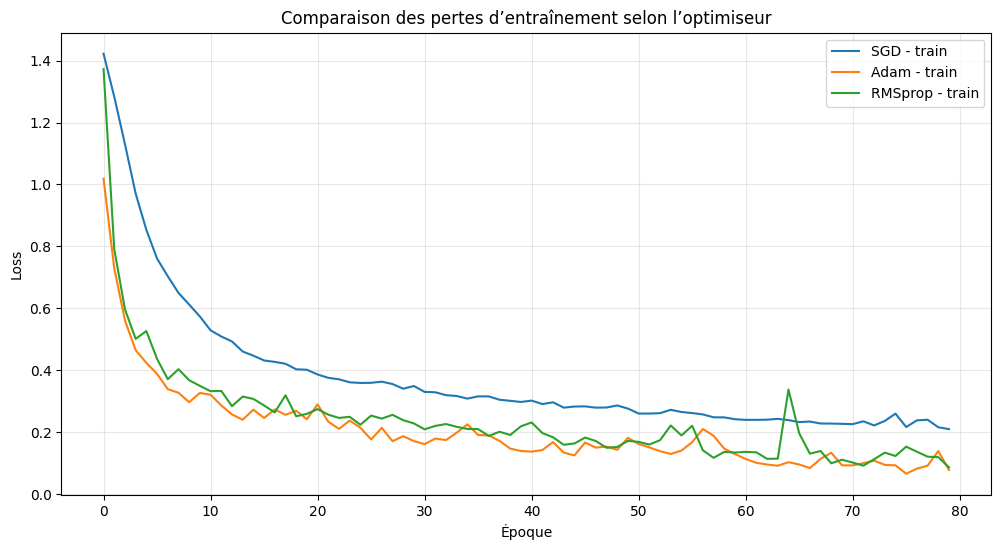

In [ ]:
plt.figure(figsize=(12, 6))
for name, hist in results.items():
    plt.plot(hist["train_losses"], label=f"{name} - train")
plt.title("Comparaison des pertes d’entraînement selon l’optimiseur")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 8. Évaluation finale

On sélectionne le meilleur optimiseur ou le plus stable, puis on évalue sur l’ensemble de test.

In [ ]:
best_optimizer = min(results, key=lambda name: results[name]["test_losses"][-1])
print("Meilleur optimiseur selon la loss de test :", best_optimizer)

final_model = FlowerMLP(input_dim=X_train.shape[1], output_dim=len(classes))
final_model = final_model

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(final_model.parameters(), lr=0.01)

for epoch in range(80):
    final_model.train()
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = final_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

final_model.eval()
all_preds = []
all_true = []
with torch.no_grad():
    for inputs, labels in test_loader:
        logits = final_model(inputs)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.numpy())
        all_true.extend(labels.numpy())

acc = accuracy_score(all_true, all_preds)
f1 = f1_score(all_true, all_preds, average="weighted")

print("Accuracy :", round(acc, 4))
print("F1-score :", round(f1, 4))
print(classification_report(all_true, all_preds, target_names=classes))

Meilleur optimiseur selon la loss de test : SGD
Accuracy : 0.7188
F1-score : 0.7322
              precision    recall  f1-score   support

         nan       0.00      0.00      0.00         2
      setosa       0.78      0.70      0.74        10
  versicolor       0.69      0.90      0.78        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.72        32
   macro avg       0.62      0.57      0.59        32
weighted avg       0.77      0.72      0.73        32



## 9. Conclusion

- Le prétraitement est crucial pour la qualité du modèle.
- La normalisation des données améliore l’apprentissage.
- Les features dérivées rendent le problème plus riche et plus instructif.
- L’optimiseur Adam est souvent plus rapide et plus stable que SGD sur ce type de données.
- Les métriques `accuracy` et `F1-score` permettent de comparer les modèles de façon objective.

### Réponse au cahier des charges
- Prétraitement : normalisation, encodage de la cible ✅
- MLP PyTorch : couches cachées, ReLU, Softmax, CrossEntropyLoss ✅
- Boucle d’entraînement complète ✅
- Comparaison des optimiseurs : SGD vs Adam vs RMSprop ✅
- Métriques : accuracy, F1-score ✅